# Inference Lab: Pricing Under Uncertainty


**Run this notebook in Google Colab.** The `demand` module is compiled for Linux and Python 3.13 only, so it will not import on a Mac or Windows machine.

The goal of this lab is to use what you've learned in this class to find the optimal price for something. You can't know for sure what the underlying curve of revenue vs price looks like. All you know is what you would know in the real world, information you gain by sampling-- you can market test any price using the demand function below. When you set the price, the market test runs for a certain amount of time, and then reports responses-- a list of 1s (bought) and 0s (didn't buy) for that price point. The total number in the sample, $n$, is therefore a random variable, given by `len(responses)`. The number of consumers who buy the product is `responses.sum().` Every time you run a market test, it takes time (literally, it will take a while to run, so don't do this lab last minute!).

In [22]:
!git clone -q https://github.com/smgroves/demand_lab.git

%cd /content/demand_lab

from demand import demand

responses = demand(price=14.0)

print(len(responses), responses.sum())

/content/demand_lab
188 155


In [23]:
import numpy as np
import pandas as pd

## 1. Compare two prices

Run one market test with price = 30. Then test price = 25. Which price earns more revenue per potential customer?

1. For each price, estimate the proportion $\hat{p}$ of customers who buy, and the revenue per customer $\hat{r}$.
2. Estimate the standard error of each $\hat{r}$ by bootstrapping.
3. Compute a 95% confidence interval for each $\hat{r}$.
4. Compute a 95% confidence interval for the difference $\hat{r}_{25} - \hat{r}_{30}$.
   
5. Interpret the estimates, SEs, and intervals. Report which price earns more profit, and how confident you are.



In [24]:
responses_25 = demand(price=25)
responses_30 = demand(price=30)

prop_buy_25 = responses_25.mean()
prop_buy_30 = responses_30.mean()

print("1:")
print(f"price = 25 proportion who buy: {prop_buy_25:.4f}, revenue per customer: {25 * prop_buy_25:.4f}")
print(f"price = 30 proportion who buy: {prop_buy_30:.4f}, revenue per customer: {30 * prop_buy_30:.4f}")

1:
price = 25 proportion who buy: 0.4694, revenue per customer: 11.7347
price = 30 proportion who buy: 0.4229, revenue per customer: 12.6857


In [25]:
b = 2000

rpc_25 = []
rpc_30 = []

for _ in range(b):
  sample_25 = pd.Series(responses_25).sample(frac=1.0, replace=True)
  sample_30 = pd.Series(responses_30).sample(frac=1.0, replace=True)

  rpc_25.append(25 * sample_25.mean())
  rpc_30.append(30 * sample_25.mean())

rpc_25_se = np.array(rpc_25).std()
rpc_30_se = np.array(rpc_30).std()

print("2:")
print(f"price = 25 RPC SE: {rpc_25_se:.4f}")
print(f"price = 30 RPC SE: {rpc_30_se:.4f}")


2:
price = 25 RPC SE: 1.2598
price = 30 RPC SE: 1.5118


In [26]:
print("3:")
print(f"price = 25 95% CI: [{25 * prop_buy_25 - (1.96 * rpc_25_se):.4f}, {25 * prop_buy_25 + (1.96 * rpc_25_se):.4f}]")
print(f"price = 30 95% CI: [{30 * prop_buy_30 - (1.96 * rpc_30_se):.4f}, {30 * prop_buy_30 + (1.96 * rpc_30_se):.4f}]")

3:
price = 25 95% CI: [9.2654, 14.2040]
price = 30 95% CI: [9.7226, 15.6488]


In [27]:
# sqrt the sum of the variances
diff_se = (rpc_25_se ** 2 + rpc_30_se ** 2) ** 0.5

print("4:")
print(f"price = 25 - price = 30 95% CI: [{25 * prop_buy_25 - 30 * prop_buy_30 - 1.96 * diff_se:.4f}, {25 * prop_buy_25 - 30 * prop_buy_30 + 1.96 * diff_se:.4f}]")

4:
price = 25 - price = 30 95% CI: [-4.8081, 2.9061]


5. The estimated revenue per customer when the price is set to 30 is about 1 dollar more than when the price is set to 25. There is slightly more variance in the revenue per customer when the price is set to 30 (intuitively this makes sense, as for a higher price, there are going to be fewer sales and more revenue per sale, so fewer sale samples are going to make up the revenue data for the higher price). There is a lot of overlap in the revenue per customer CIs for the two prices tested, as evidenced by the CI for the difference, which overlaps with 0 by a large margin on both sides.

## 2. The cost of sampling

7. Run a second market test at each price. Pool the two price = 30 samples (`np.concatenate`), and pool the two price = 25 samples.
8. Recompute the SEs, the intervals, and the interval for the difference. By roughly what factor did the SE shrink? Explain why, using the SE formula.
   
9.  **Was the extra sampling worth it?** Every market test takes time, and while you're testing you aren't selling at your best price, so each test costs the company revenue. Did the first round already settle the question (its difference interval excluded 0)? If so, the second round cost time and bought nothing but a narrower interval. If not, did the second round settle it?


In [ ]:
responses_25_new = np.concatenate((responses_25, demand(price=25)))
responses_30_new = np.concatenate((responses_30, demand(price=30)))

In [31]:
prop_buy_25 = responses_25_new.mean()
prop_buy_30 = responses_30_new.mean()

print("8:")
print(f"price = 25 proportion who buy: {prop_buy_25:.4f}, revenue per customer: {25 * prop_buy_25:.4f}")
print(f"price = 30 proportion who buy: {prop_buy_30:.4f}, revenue per customer: {30 * prop_buy_30:.4f}")


rpc_25 = []
rpc_30 = []

for _ in range(b):
  sample_25 = pd.Series(responses_25_new).sample(frac=1.0, replace=True)
  sample_30 = pd.Series(responses_30_new).sample(frac=1.0, replace=True)

  rpc_25.append(25 * sample_25.mean())
  rpc_30.append(30 * sample_25.mean())

rpc_25_se = np.array(rpc_25).std()
rpc_30_se = np.array(rpc_30).std()

print("")
print(f"price = 25 RPC SE: {rpc_25_se:.4f}")
print(f"price = 30 RPC SE: {rpc_30_se:.4f}")

print("")
print(f"price = 25 95% CI: [{25 * prop_buy_25 - (1.96 * rpc_25_se):.4f}, {25 * prop_buy_25 + (1.96 * rpc_25_se):.4f}]")
print(f"price = 30 95% CI: [{30 * prop_buy_30 - (1.96 * rpc_30_se):.4f}, {30 * prop_buy_30 + (1.96 * rpc_30_se):.4f}]")

# sqrt the sum of the variances
diff_se = (rpc_25_se ** 2 + rpc_30_se ** 2) ** 0.5

print("")
print(f"price = 25 - price = 30 95% CI: [{25 * prop_buy_25 - 30 * prop_buy_30 - 1.96 * diff_se:.4f}, {25 * prop_buy_25 - 30 * prop_buy_30 + 1.96 * diff_se:.4f}]")


7:
price = 25 proportion who buy: 0.3759, revenue per customer: 9.3966
price = 30 proportion who buy: 0.3814, revenue per customer: 11.4414

price = 25 RPC SE: 0.7180
price = 30 RPC SE: 0.8617

price = 25 95% CI: [7.9892, 10.8039]
price = 30 95% CI: [9.7526, 13.1303]

price = 25 - price = 30 95% CI: [-4.2433, 0.1535]


9. The second round of testing reduced the SEs for each price's revenue per customer, but hasn't generated confidence beyond 95% that the two prices produce meaningfully different revenues per customer. The difference in the revenues per customer has increased, but the confidence interval for the difference still includes 0.

## 3. Finding the optimal price

Now find the price that maximizes revenue per customer. Search prices between about \$5 and \$100.

Every market test takes time, and time spent testing is revenue lost: while you test, you aren't selling at your best price. Your confidence intervals tell you whether another test is worth running. **Use as few market tests as you can (<25 would be good).** Your grade will be based on, in this order, whether you:
- accurately used the information you have by accurately interpreting confidence intervals
- found a good price, close to the optimal price
- and used fewer tests.

If this sounds fun to you, run with it! If you are still very confused about what to do, read the hints below.

<details><Summary>Hints</summary>
<b>Hint 1:</b> There are a few ways you could search:

- Brute force: test every price on a fine grid. This takes a market test at every price, including prices that are obviously bad. This would be a bad choice.
- Hill climbing: compare the CI for two prices, move toward the better one, and repeat. For example, start from the 25/30 comparison above; based on which price is better, choose another price \$10 away in that direction (15 if 25 was better; 40 if 30 was better). Shrink the step size as you get close to a good price. If you can't detect a difference between two prices, either shrink the step size or increase the sample size (i.e. run another market test at the same price).
- other strategies that I won't mention here.
  
<b>Hint 2:</b> You may want to try starting your tests with a few different prices across the range; there may be local maxima you will get stuck in if you just hill climb towards a single maximum.

<b>Hint 3:</b> You can make up your own strategy or try a mix of strategies. However, keep in mind that your grade will reflect how well you ran A/B testing and interpreting confidence intervals, more than how complex your strategy is. Similarly, a lucky guess with a brute force strategy would not be a good reproducible strategy.

<b>Hint 4:</b>
Turn your code from part 1 into a function, so you can easily input responses, run bootstrapping, calculate SE, and calculate confidence intervals. Then make another function where you give it two confidence intervals and make a decision based on them: sample more at the same test, or move in one direction with some step size.
   </details>

**Before you run any tests,** write down your plan: which prices you'll test first, how you'll decide where to go next, and what your intervals need to show before you stop. Then follow it, and note anywhere you changed course and why.

For any method, stop when your intervals show that another test is unlikely to change your answer by enough to matter.

**Deliverable:** A ~2-3 paragraph write up of the strategy you chose, your final recommended price, a 95% CI for $r$ at that price, the number of market tests you ran, and one or two sentences on how your intervals told you when to stop.

*Initially, I was trying to implement things in here, but my while loop was never ending, so I went back to the extra help notebook and figured out that I could test things over there. I also didn't appreciate that I could just copy a bunch of code from the extra help file over here, so the previous parts are my own concoction for the problems.*

**Plan**: Run testing in 2 phases:
- **Phase 1**: A coarser search over a broader range of possible values. Starting with price = 10 (a good baseline, as the current tests give close to 10 revenue per customer, which is the max for 10, if everyone buys), increase the price value until the revenue per customer is close to 0 (the price becomes too high to the point where no one buys). Calculate revenue per customer, and standard error in the revenue per customer for each price tested. Multiply the previous price tested by 1.15 (a value that seemed decent on the practice demand) to get a new price.
- **Phase 2**: Take the maximum revenue per customer from the prices tested, and build a list of all other prices whose 95% confidence intervals for the revenue per customer overlap with the CI for the maximum revenue per customer price. From there, run an additional market test for each of these prices and filter the new list to only prices that have revenue per customer CIs that overlap with the new max's CI. From there, test prices in between the remaining prices, and then take the maximum average revenue per customer from the prices tested and use that.

In [36]:
results = []

total_tests = 0

price = 10
last_avg_rpc = 0

# Go until the avg revenue per customer for the last test is below 5, and go
# until at least price = 35
while price < 35 or last_avg_rpc > 5:
  # Run 2 market tests at the price and pool the results
  responses = demand(price=price)
  total_tests += 1

  last_avg_rpc = price * responses.mean()

  print(f"Price: {price:.2f}, Revenue per Customer: {last_avg_rpc:.3f}")

  b = 2000

  rpcs = []

  for _ in range(b):
    sample = pd.Series(responses).sample(frac=1.0, replace=True)

    rpcs.append(price * sample.mean())

  rpc_se = np.array(rpcs).std()

  results.append({'price': price, 'avg_rpc': last_avg_rpc, 'rpc_se': rpc_se, 'tests': 2, 'index': total_tests, 'responses': responses})

  price *= 1.25

print(f"Max price tested: {price / 1.25}, total tests: {total_tests}")

Price: 10.00, Revenue per Customer: 9.579
Price: 12.50, Revenue per Customer: 11.561
Price: 15.62, Revenue per Customer: 9.423
Price: 19.53, Revenue per Customer: 8.061
Price: 24.41, Revenue per Customer: 9.478
Price: 30.52, Revenue per Customer: 11.600
Price: 38.15, Revenue per Customer: 14.453
Price: 47.68, Revenue per Customer: 14.788
Price: 59.60, Revenue per Customer: 13.780
Price: 74.51, Revenue per Customer: 18.626
Price: 93.13, Revenue per Customer: 14.067
Price: 116.42, Revenue per Customer: 0.000
Max price tested: 116.41532182693481, total tests: 12


Text(0, 0.5, 'Revenue per Customer')

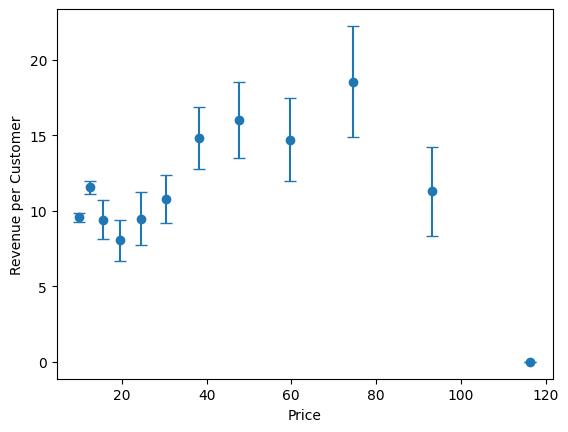

In [47]:
import matplotlib.pyplot as plt

plt.errorbar([res['price'] for res in results], [res['avg_rpc'] for res in results], yerr=[1.96 * res['rpc_se'] for res in results], fmt="o", capsize=4, label="one market test: r_hat ± 1.96 SE")
plt.xlabel('Price')
plt.ylabel('Revenue per Customer')

<ErrorbarContainer object of 3 artists>

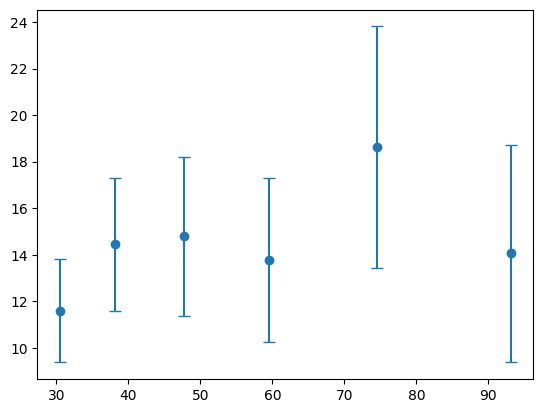

In [39]:
# Calculate the index in the list for best price so far
best = 0
best_rpc = 0

for i, res in enumerate(results):
    if res['avg_rpc'] > best_rpc:
        best_rpc = res['avg_rpc']
        best = i

# Filter results to only include overlapping rpc CIs with the max
filtered_results = [res for res in results if res['avg_rpc'] + 1.96 * res['rpc_se'] > results[best]['avg_rpc'] - 1.96 * results[best]['rpc_se']]

plt.errorbar([res['price'] for res in filtered_results], [res['avg_rpc'] for res in filtered_results], yerr=[1.96 * res['rpc_se'] for res in filtered_results], fmt="o", capsize=4, label="one market test: r_hat ± 1.96 SE")

<ErrorbarContainer object of 3 artists>

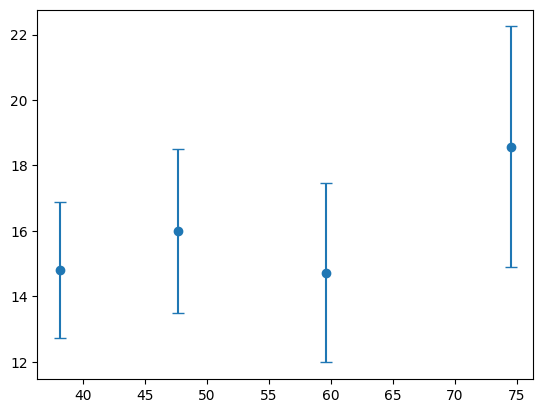

In [40]:
# Run an additional test for each of these filtered results and filter for CI overlap with the new max
for i in range(len(filtered_results)):
    new_results = demand(price=filtered_results[i]['price'])
    total_tests += 1

    filtered_results[i]['responses'] = np.concatenate([filtered_results[i]['responses'], new_results])

    filtered_results[i]['avg_rpc'] = filtered_results[i]['price'] * filtered_results[i]['responses'].mean()

    b = 2000

    rpcs = []

    for _ in range(b):
        sample = pd.Series(filtered_results[i]['responses']).sample(frac=1.0, replace=True)

        rpcs.append(filtered_results[i]['price'] * sample.mean())

    filtered_results[i]['rpc_se'] = np.array(rpcs).std()


# Calculate the index in the list for best price so far
best = 0
best_rpc = 0

for i, res in enumerate(filtered_results):
    if res['avg_rpc'] > best_rpc:
        best_rpc = res['avg_rpc']
        best = i

# Filter results to only include overlapping rpc CIs with the max
filtered_results = [res for res in filtered_results if res['avg_rpc'] + 1.96 * res['rpc_se'] > filtered_results[best]['avg_rpc'] - 1.96 * filtered_results[best]['rpc_se']]

plt.errorbar([res['price'] for res in filtered_results], [res['avg_rpc'] for res in filtered_results], yerr=[1.96 * res['rpc_se'] for res in filtered_results], fmt="o", capsize=4, label="one market test: r_hat ± 1.96 SE")


In [41]:
print(f"Total tests so far: {total_tests}")

Total tests so far: 18


Now, realistically, I think using additional tests at this stage in the analysis would be justified, as the differences in revenue would be smaller, and running tests on slightly less-optimal prices values wouldn't hurt business interests that much.

<ErrorbarContainer object of 3 artists>

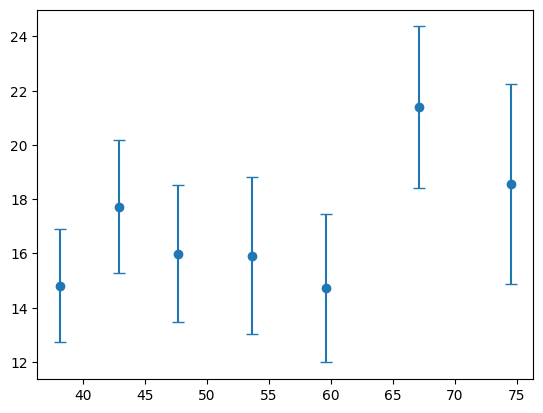

In [43]:
# add more testing points halfway between the price points we have currently
new_prices = []

for i in range(len(filtered_results) - 1):
  # create new testing prices halfway between the remaining points we half
  new_prices.append((filtered_results[i]['price'] + filtered_results[i + 1]['price']) / 2)

for new_price in new_prices:
  # do 2 tests initially here
  new_responses = np.concat([demand(price=new_price), demand(price=new_price)])
  total_tests += 2

  avg_rpc = new_price * new_responses.mean()

  b = 2000

  rpcs = []

  for _ in range(b):
      sample = pd.Series(new_responses).sample(frac=1.0, replace=True)

      rpcs.append(new_price * sample.mean())

  rpc_se = np.array(rpcs).std()

  filtered_results.append({'price': new_price, 'avg_rpc': avg_rpc, 'rpc_se': rpc_se, 'tests': 2, 'index': total_tests, 'responses': new_responses})

plt.errorbar([res['price'] for res in filtered_results], [res['avg_rpc'] for res in filtered_results], yerr=[1.96 * res['rpc_se'] for res in filtered_results], fmt="o", capsize=4, label="one market test: r_hat ± 1.96 SE")

In [44]:
print(f"Total tests so far: {total_tests}")

Total tests so far: 24


In [50]:
# Calculate the index in the list for best price so far
best_rpc = filtered_results[0]

for i, res in enumerate(filtered_results):
    if res['avg_rpc'] > best_rpc['avg_rpc']:
        best_rpc = res

print(f"Best price: {best_rpc['price']:.2f}, best rpc: {best_rpc['avg_rpc']:.2f}")
print(f"Confidence interval for revenue per customer: [{best_rpc['avg_rpc'] - 1.96 * best_rpc['rpc_se']:.2f}, {best_rpc['avg_rpc'] + 1.96 * best_rpc['rpc_se']:.2f}]")

Best price: 67.06, best rpc: 21.39
Confidence interval for revenue per customer: [18.42, 24.37]


At this point, I've pretty much exhausted the suggested number of tests, and while I think that it wouldn't do much harm to keep going, I'll stop here. The best price I found was roughly 67 (which is also good on the marketing front), with a corresponding revenue per customer (from the tests) of 21.39.

### Report

**Deliverable:** A ~2-3 paragraph write up of the strategy you chose, your final recommended price, a 95% CI for $r$ at that price, the number of market tests you ran, and one or two sentences on how your intervals told you when to stop.

The strategy I chose for evaluating the best price to optimize involves two phases. In the first phase, I iterate over a wider range of price values to get a baseline for the distribution of corresponding revenues per price. I start with price = 10, and increase the price by 25% until the corresponding revenue per price drops to close to 0. Increasing by a percent instead of a fixed number allows for more efficient coverage of a wider range of price values, as I have no idea how large the optimal price may be. The second phase involves drilling down into the better prices, in order to more precisely optimize the revenue per price. I started by filtering price values to only prices where the corresponding revenue per price's 95% CI overlapped with the best revenue per prices's 95% CI%. For all price values in that filtered set, I ran another market test for each, and then filtered using the same method. At that point, I was down to 4 price points, so in order to increase the precision of the test, I added 3 new price points half way in between each of the remaining 4. I ran 2 market tests for each of these new price points, and then picked the price that gave the highest revenue per customer.

When I stopped, I had run a total of 24 market tests. Realistically, I would run more tests using the same methodology, as testing smaller adjustments near the the optimal value won't cost the company much in lost revenue. When I stopped, there was still overlap in the confidence intervals for the price values left, which isn't ideal, but more tests would be needed to further shrink the CIs. My final recommended price from testing is 67 dollars, with the corresponding revenue per customer being expected to fall within [18.42, 24.37] at 95% confidence.